__aims__: 
- Use these V2 screens for ScreenPro2 DevOps

__tasks__: 
- [ ] compare ScreenProcessing guide level scores with ScreenPro2 scores.

In [68]:
!pip uninstall -y screenpro2
!pip install git+https://github.com/ArcInstitute/ScreenPro2.git@cli

Found existing installation: ScreenPro2 0.3.1
Uninstalling ScreenPro2-0.3.1:
  Successfully uninstalled ScreenPro2-0.3.1
  Cloning https://github.com/ArcInstitute/ScreenPro2.git (to revision cli) to /tmp/pip-req-build-serbyp8k
  Running command git clone --filter=blob:none --quiet https://github.com/ArcInstitute/ScreenPro2.git /tmp/pip-req-build-serbyp8k
  Running command git checkout -b cli --track origin/cli
  Switched to a new branch 'cli'
  branch 'cli' set up to track 'origin/cli'.
  Resolved https://github.com/ArcInstitute/ScreenPro2.git to commit 0496c65212bfcfc6fe4b11513d77ab4e94209037
  Preparing metadata (setup.py) ... done
  Created wheel for ScreenPro2: filename=ScreenPro2-0.3.1-py3-none-any.whl size=29563 sha256=9b57c36faf646ec4ccd2409266216fabecde9d31830055bcb2c640dc7823fbef
  Stored in directory: /tmp/pip-ephem-wheel-cache-nnw0cl6k/wheels/54/6f/ca/9066922c405038561e61fc6853c36bd93f9c425e91437c616f
Successfully built ScreenPro2


In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import screenpro as scp
from venn import venn
from glob import glob
import blitzgsea as blitz
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib import rcParams, rc_context
from matplotlib import font_manager as fm

from matplotlib import rcParams, rc_context

font_files = fm.findSystemFonts(fontpaths=None, fontext='ttf')

for font_file in font_files:
    fm.fontManager.addfont(font_file)

# {f.name for f in matplotlib.font_manager.fontManager.ttflist}

rcParams['font.family'] = ['Arial']

In [2]:
# pagerdir='/data_gilbert/home/aarab/tools/pager'

In [3]:
# msigdb_c5_go_gmt = blitz.enrichr.read_gmt(
#     f'{pagerdir}/annotations/human/msigdb_v7.4_c5.go/c5.go.v7.4.symbols.gmt'
# )

In [4]:
# !pip install blitzgsea

# 
Gather data

In [5]:
# # get counts
# for exp_id in ['hl60_exp1','skm1_exp','molm13_exp']:
#     for table_id in ['phenotypetable','mergedcountstable','genetable_collapsed']:
#         !wget -P dac_screens/{exp_id}/ \
#             https://raw.githubusercontent.com/GilbertLabUCSF/Decitabine-treatment/main/DAC/CRISPRi-screen/{exp_id}/{table_id}.txt &> /dev/null

In [6]:
# # http://humantfs.ccbr.utoronto.ca/download.php
# # TF gene names (.txt)
# !wget -P ../annotations http://humantfs.ccbr.utoronto.ca/download/v_1.01/TF_names_v_1.01.txt

In [7]:
# TFs_list = pd.read_csv('../annotations/TF_names_v_1.01.txt',header=None)[0].to_list()

## Run ScreenPro2

In [8]:
CRISPRi_v2_human_path = '../../../ScreenPro2/library_tables/CRISPRi_v2_human_librarytable.txt.gz'

In [9]:
fq_dir = '../dac_screens/molm13_exp/fastq/'

samples = []

for fq_file in glob(f'{fq_dir}/*.fastq.gz'):
    sample_id = fq_file.split('/')[-1].replace('.fastq.gz','')
    # sample_id = fq_file.split('/')[1].split('.')[0].split('_S')[0]
    samples.append(sample_id)

samples.sort()

samples

['DAC_Rep1', 'DAC_Rep2', 'DMSO_Rep1', 'DMSO_Rep2', 'T0_Rep1', 'T0_Rep2']

In [10]:
counter = scp.ngs.Counter(cas_type = 'cas9', library_type = 'single_guide_design')
counter.load_library(CRISPRi_v2_human_path, sep = '\t', verbose = True, index_col=None, protospacer_length=19)

Trimming protospacer sequences in 'protospacer' column.
Library table successfully loaded.


In [25]:
counter.get_counts_matrix(
    fastq_dir = fq_dir,
    samples = samples,
    trim_first_g=True,
    # write = 'force',
    verbose = True
)

DAC_Rep1
count file exists ...
% mapped reads 92.85640738917253
DAC_Rep2
count file exists ...
% mapped reads 92.70175728442209
DMSO_Rep1
count file exists ...
% mapped reads 92.75022766937407
DMSO_Rep2
count file exists ...
% mapped reads 92.82737460171128
T0_Rep1
count file exists ...
% mapped reads 93.15065854171453
T0_Rep2
count file exists ...
% mapped reads 93.073513998814


In [40]:
adata = counter.build_counts_anndata()

adata.obs = pd.DataFrame(
    adata.obs.index.str.split('_').to_list(),
    columns = ['condition','replicate'],
    index = adata.obs.index
)
adata.obs['replicate'] = adata.obs['replicate'].str[-1].astype(int)

molm13_db = {
    "DMSO":10.04,
    "DAC":7.46,
}

adata.obs['pop_doublings'] = [
    molm13_db['DAC'],     molm13_db['DAC'],
    molm13_db['DMSO'],     molm13_db['DMSO'],
    np.nan, np.nan
]

adata.var['targetType'] = 'gene'
adata.var.loc[adata.var.target.eq('negative_control'),'targetType'] = 'negCtrl'

In [41]:
molm13_screen = scp.PooledScreens(adata, n_reps=2, fc_transformation='log2(x+1)')

scp.utils.find_low_counts(molm13_screen.adata)

106625 variables with less than 50 reads in either replicates / experiment


In [42]:
molm13_screen.adata.var.groupby(['targetType', 'low_count']).size()

targetType  low_count
gene        False        100599
            True         104681
negCtrl     False          1846
            True           1944
dtype: int64

In [43]:
molm13_screen.adata = molm13_screen.adata[:,~molm13_screen.adata.var.low_count].copy()
molm13_screen.adata.var.drop(columns='low_count',inplace=True)

molm13_screen.countNormalization()

# sc.pp.log1p(molm13_screen.adata)

In [44]:
molm13_screen.phenotypes = {}
molm13_screen.phenotype_names = []

In [45]:
molm13_screen.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    db_untreated=10.04,
    db_treated=7.46,
    score_level='compare_guides',
    # keep_top_n = 3
)

	DMSO vs T0


/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1103: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1103: RuntimeWarning: invalid value encountered in multiply
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero


	DAC vs T0


/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1103: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1103: RuntimeWarning: invalid value encountered in multiply
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero


	DAC vs DMSO


/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1103: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1103: RuntimeWarning: invalid value encountered in multiply
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero


- score distribution

In [46]:
molm13_screen.phenotypes['compare_guides']

gamma:DMSO_vs_T0              tau:DAC_vs_T0               \
                       score ttest pvalue         score ttest pvalue   
A1BG                0.013181     0.296213     -0.010392     0.518971   
A1CF                0.031303     0.374229      0.027207     0.519197   
A2M                -0.039566     0.125175     -0.057072     0.055099   
A2ML1              -0.009312     0.461362     -0.001822     0.725648   
A3GALT2            -0.083849     0.503440     -0.012775     0.654118   
...                      ...          ...           ...          ...   
pseudo_9975         0.024832     0.266994      0.101813     0.096224   
pseudo_9980        -0.035271     0.231373      0.002246     0.429463   
pseudo_9985        -0.031617     0.481855     -0.046985     0.688753   
pseudo_9990         0.031143     0.170297     -0.021031     0.764820   
pseudo_9995         0.028740     0.229753      0.020251     0.364250   

            rho:DAC_vs_DMSO               
                      score ttest pvalue  
A1BG              -0.081341     0.581436  
A1CF              -0.043146     0.256602  
A2M               -0.011051     0.720169  
A2ML1              0.030969     0.490114  
A3GALT2            0.289358     0.560853  
...                     ...          ...  
pseudo_9975       -0.032991     0.658781  
pseudo_9980        0.056085     0.476763  
pseudo_9985        0.014788     0.096917  
pseudo_9990       -0.055692     0.556758  
pseudo_9995       -0.001466     0.406882  

[37800 rows x 6 columns]

In [47]:
# molm13_screen.getPhenotypeScores(
#     'compare_guides',
#     'gamma:DMSO_vs_T0'
# )

- p-value distribution

### Load ScreenProcessing

In [48]:
data_dir = '../dac_screens/'
screens = {}

for exp in ['hl60_exp1','molm13_exp','skm1_exp']:
    name = exp.split('_')[0]
    cnt = pd.read_csv(f'{data_dir}/{exp}/mergedcountstable.txt',sep='\t', header=list(range(2)),index_col=list(range(1)))
    meta = cnt.columns.to_frame().reset_index(drop=True)
    samples = [f'{exp}_sample_{i+1}' for i in meta.index.to_list()]
    cnt.columns = samples
    meta.index = samples
    meta.columns = ['condition','replicate']
    meta.replicate = meta.replicate.str[-1].astype(int)
    
    oligo = cnt.index.to_frame()
    oligo.index.name = None
    oligo['target'] = oligo.sgId.str.split('_').str[0]
    del oligo['sgId']
    oligo['targetType'] = oligo.target.apply(lambda x: "negCtrl" if x == "non-targeting" else "targeting")
    oligo = oligo.sort_values('target').sort_values('targetType',ascending=False)
    oligo.targetType = pd.Categorical(oligo.targetType,categories=['targeting','negCtrl'])
    
    adat = ad.AnnData(X=cnt.loc[oligo.index,:].T.astype(float), var=oligo, obs=meta)
    # scp.utils.find_low_counts(adat)
    
    phenotypetable = pd.read_csv(f'{data_dir}/{exp}/phenotypetable.txt',sep='\t',header=[0,1],index_col=0)
    genetable = pd.read_csv(f'{data_dir}/{exp}/genetable_collapsed.txt',sep='\t',header=[0,1,2],index_col=0)
    
    screens[name] = scp.PooledScreens(adat, n_reps=2, fc_transformation='log2(x+1)')
    screens[name].phenotypes.update({
        'genetable':genetable
    })

    screens[name].pdata = ad.AnnData(pd.concat([
        phenotypetable['gamma'][['Rep1','Rep2']].add_prefix('gamma_'),
        phenotypetable['tau'][['Rep1','Rep2']].add_prefix('tau_'),
        phenotypetable['rho'][['Rep1','Rep2']].add_prefix('rho_')
    ],axis=1).T)
    screens[name].pdata.obs['replicate'] = screens[name].pdata.obs.index.str[-1].astype(int)
    screens[name].pdata.var = adat.var.loc[screens[name].pdata.var.index,:]

In [49]:
screens['molm13'].adata.var['sequence'] = counter.library.to_pandas().set_index('sgID').loc[screens['molm13'].adata.var.index,'sequence']

In [50]:
molm13_db = {
    "DMSO":10.04,
    "DAC":7.46,
}

screens['molm13'].adata.obs['pop_doublings'] = [
    molm13_db['DAC'],     molm13_db['DAC'],
    molm13_db['DMSO'],     molm13_db['DMSO'],
    np.nan, np.nan
]


In [51]:
screens['molm13'].countNormalization()

In [53]:
# screens['molm13'].calculateDrugScreen(
#     t0 = 'T0',
#     untreated = 'DMSO',
#     treated = 'DAC',
#     db_untreated=10.04,
#     db_treated=7.46,
#     score_level='compare_guides',
#     keep_top_n = 3
# )

In [55]:
# rho_screenpro2_with_screenprocessing_counts = scp.utils.ann_score_df(
#     screens['molm13'].phenotypes['compare_guides']['rho:DAC_vs_DMSO']['replicate_ave'].reset_index(),
#     ctrl_label='pseudo',
#     threshold=2.5
# )
# # rho_screenpro2.pvalue.fillna(1,inplace=True)

In [56]:
# rho_screenpro2_with_screenprocessing_counts.groupby('label').size()

In [65]:
rho_screenpro2 = scp.utils.ann_score_df(
    molm13_screen.phenotypes['compare_guides']['rho:DAC_vs_DMSO'].reset_index(),
    ctrl_label='pseudo',
    threshold=2
)
# rho_screenpro2.pvalue.fillna(1,inplace=True)

In [66]:
rho_screenpro2.groupby('label').size()

label
sensitivity_hit      210
resistance_hit       266
pseudo             18900
target_non_hit     18424
dtype: int64

In [62]:
rho_screenprocessing = scp.utils.ann_score_df(
    screens['molm13'].phenotypes['genetable']['rho']['ave_Rep1_Rep2'][[
        'average phenotype of strongest 3',
        'Mann-Whitney p-value',
    ]].reset_index(),
    ctrl_label='pseudo',
    threshold=3.5
)

In [63]:
rho_screenprocessing.groupby('label').size()

label
sensitivity_hit      271
resistance_hit       285
pseudo             18905
target_non_hit     18349
dtype: int64

- check 200 hits from screenprocessing 

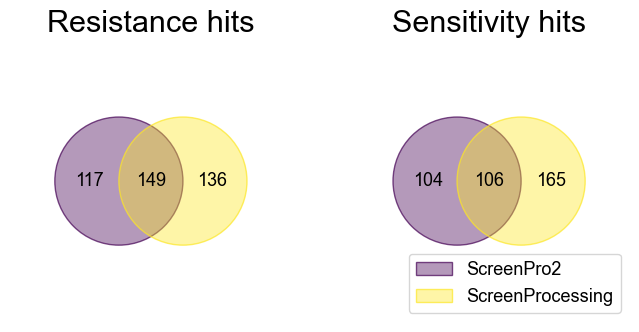

In [67]:
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(8,4))

# draw venn diagram
venn({
    'ScreenPro2':set(rho_screenpro2.query('label == "resistance_hit"').target.to_list()),
    'ScreenProcessing':set(rho_screenprocessing.query('label == "resistance_hit"').target.to_list()),
}, ax=ax1, legend_loc=None)

ax1.set_title('Resistance hits', fontsize=22)

venn({
    'ScreenPro2':set(rho_screenpro2.query('label == "sensitivity_hit"').target.to_list()),
    'ScreenProcessing':set(rho_screenprocessing.query('label == "sensitivity_hit"').target.to_list()),
}, ax=ax2, legend_loc='lower right')

ax2.set_title('Sensitivity hits', fontsize=22)

plt.title('Sensitivity hits', fontsize=22)
plt.show()

- hits

In [69]:
# fig, (ax1,ax2) = plt.subplots(1,2,figsize=(8,4))

# # draw venn diagram
# venn({
#     'ScreenPro2':set(rho_screenpro2_with_screenprocessing_counts.query('label == "resistance_hit"').target.to_list()),
#     'ScreenProcessing':set(rho_screenprocessing.query('label == "resistance_hit"').target.to_list()),
# }, ax=ax1, legend_loc=None)

# ax1.set_title('Resistance hits', fontsize=22)

# venn({
#     'ScreenPro2':set(rho_screenpro2_with_screenprocessing_counts.query('label == "sensitivity_hit"').target.to_list()),
#     'ScreenProcessing':set(rho_screenprocessing.query('label == "sensitivity_hit"').target.to_list()),
# }, ax=ax2, legend_loc='lower right')

# ax2.set_title('Sensitivity hits', fontsize=22)

# plt.title('Sensitivity hits', fontsize=22)
# plt.show()

- check 200 hits from screenprocessing 

In [70]:
rho_screenprocessing.score.max(), rho_screenprocessing.score.min(), np.log10(rho_screenprocessing.pvalue).min()

(1.4424812711014874, -2.8978422865806577, -3.6744794842845296)

In [90]:
rho_screenpro2.score.max(), rho_screenpro2.score.min(), np.log10(rho_screenpro2.pvalue).min()

(0.8998865239409322, -0.787552068320048, -2.1630635437792654)

In [ ]:
# rho_screenpro2_with_screenprocessing_counts.score.max(), rho_screenpro2_with_screenprocessing_counts.score.min(), np.log10(rho_screenpro2_with_screenprocessing_counts.pvalue).min()

In [88]:
# rho_screenprocessing.sort_values('score',ascending=True).head(15)

In [89]:
# rho_screenpro2.sort_values('score',ascending=True).head(15)

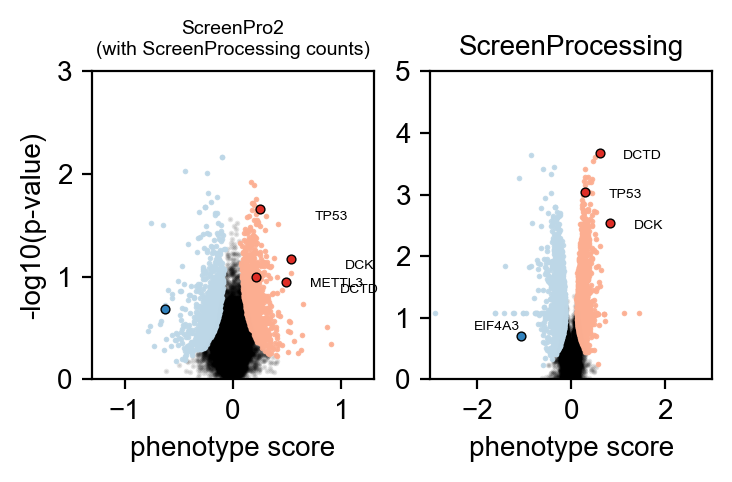

In [91]:
_, (ax1,ax2) = plt.subplots(1,2, figsize=(4,2), dpi = 200)

scp.pl.plot_volcano(ax1, rho_screenpro2.drop(columns='label'), threshold=1, ctrl_label='pseudo')
scp.pl.label_resistance_hit(ax1, rho_screenpro2.drop(columns='label'), label='DCK', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_resistance_hit(ax1, rho_screenpro2.drop(columns='label'), label='DCTD', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_resistance_hit(ax1, rho_screenpro2.drop(columns='label'), label='TP53', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_resistance_hit(ax1, rho_screenpro2.drop(columns='label'), label='METTL3', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_sensitivity_hit(ax1, rho_screenpro2.drop(columns='label'), label='EIF4A3', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5, t_x=-1, t_y=0.1)

ax1.set_xlim(-1.3,1.3)
ax1.set_ylim(0, 3)
ax1.set_title('ScreenPro2\n(with ScreenProcessing counts)', fontsize=7)

scp.pl.plot_volcano(ax2, rho_screenprocessing.drop(columns='label'), threshold=1, ctrl_label='pseudo')
scp.pl.label_resistance_hit(ax2, rho_screenprocessing.drop(columns='label'), label='DCK', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_resistance_hit(ax2, rho_screenprocessing.drop(columns='label'), label='DCTD', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_resistance_hit(ax2, rho_screenprocessing.drop(columns='label'), label='TP53', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_sensitivity_hit(ax2, rho_screenprocessing.drop(columns='label'), label='EIF4A3', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5, t_x=-1, t_y=0.1)

ax2.set_ylabel('')
ax2.set_ylim(0,5)
ax2.set_xlim(-3,3)
ax2.set_title('ScreenProcessing', fontsize=10)
# ax2.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=0.5, alpha=0.5)

for ax in [ax1,ax2]:
    ax.get_legend().remove()

plt.show()

/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)

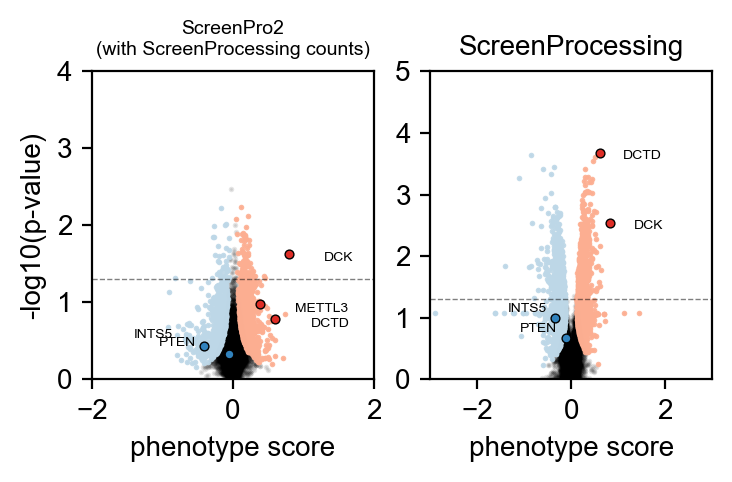

In [126]:
_, (ax1,ax2) = plt.subplots(1,2, figsize=(4,2), dpi = 200)

scp.pl.plot_volcano(ax1, rho_screenpro2_with_screenprocessing_counts.drop(columns='label'), threshold=1, ctrl_label='pseudo')
scp.pl.label_resistance_hit(ax1, rho_screenpro2_with_screenprocessing_counts.drop(columns='label'), label='DCK', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_resistance_hit(ax1, rho_screenpro2_with_screenprocessing_counts.drop(columns='label'), label='DCTD', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_resistance_hit(ax1, rho_screenpro2_with_screenprocessing_counts.drop(columns='label'), label='METTL3', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_sensitivity_hit(ax1, rho_screenpro2_with_screenprocessing_counts.drop(columns='label'), label='INTS5', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5, t_x=-1, t_y=0.1)
scp.pl.label_sensitivity_hit(ax1, rho_screenpro2_with_screenprocessing_counts.drop(columns='label'), label='PTEN', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5, t_x=-1, t_y=0.1)

ax1.set_xlim(-2,2)
ax1.set_ylim(0, 4)
ax1.set_title('ScreenPro2\n(with ScreenProcessing counts)', fontsize=7)
ax1.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=0.5, alpha=0.5)

scp.pl.plot_volcano(ax2, rho_screenprocessing.drop(columns='label'), threshold=1, ctrl_label='pseudo')
scp.pl.label_resistance_hit(ax2, rho_screenprocessing.drop(columns='label'), label='DCK', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_resistance_hit(ax2, rho_screenprocessing.drop(columns='label'), label='DCTD', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5)
scp.pl.label_sensitivity_hit(ax2, rho_screenprocessing.drop(columns='label'), label='INTS5', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5, t_x=-1, t_y=0.1)
scp.pl.label_sensitivity_hit(ax2, rho_screenprocessing.drop(columns='label'), label='PTEN', threshold=1, ctrl_label='pseudo', size = 10, size_txt=5, t_x=-1, t_y=0.1)

ax2.set_ylabel('')
ax2.set_ylim(0,5)
ax2.set_xlim(-3,3)
ax2.set_title('ScreenProcessing', fontsize=10)
ax2.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=0.5, alpha=0.5)

for ax in [ax1,ax2]:
    ax.get_legend().remove()

plt.show()

# 

/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/scanpy/preprocessing/_simple.py:377: RuntimeWarning: invalid value encountered in log1p
  np.log1p(X, out=X)


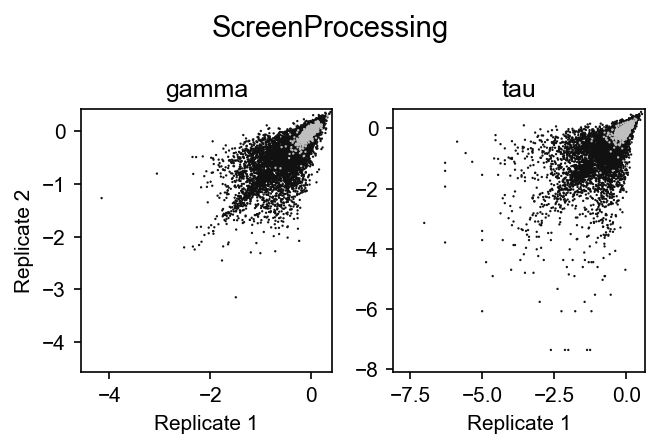

In [235]:
_, (ax1,ax2) = plt.subplots(1,2,figsize=(4.5,3),dpi=150)

scp.pl.plotReplicateScatter(ax1, screens['molm13'].pdata, 'gamma_Rep1','gamma_Rep2', title='gamma')
scp.pl.plotReplicateScatter(ax2, screens['molm13'].pdata, 'tau_Rep1','tau_Rep2', title='tau')
ax2.set_ylabel('')

plt.suptitle('ScreenProcessing', fontsize=12)
plt.tight_layout()
plt.show()

/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/scanpy/preprocessing/_simple.py:377: RuntimeWarning: invalid value encountered in log1p
  np.log1p(X, out=X)


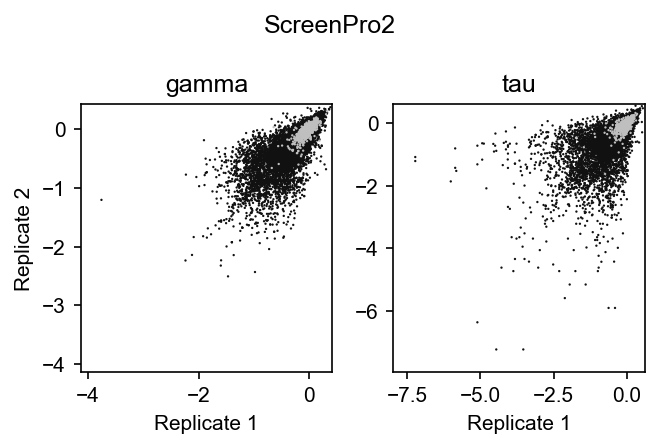

In [236]:
_, (ax1,ax2) = plt.subplots(1,2,figsize=(4.5,3),dpi=150)

scp.pl.plotReplicateScatter(ax1, molm13_screen.pdata,'gamma_replicate_1','gamma_replicate_2', title='gamma')
scp.pl.plotReplicateScatter(ax2, molm13_screen.pdata,'tau_replicate_1','tau_replicate_2', title='tau')
ax2.set_ylabel('')

plt.suptitle('ScreenPro2')
plt.tight_layout()
plt.show()

In [35]:
# _, (ax1,ax2) = plt.subplots(1,2,figsize=(4.5,3),dpi=150)

# pd.DataFrame({
#     'ScreenPro2':molm13_screen.pdata.to_df().loc['rho_replicate_1',:],
#     'ScreenProcessing':screens['molm13'].pdata.to_df().loc['rho_Rep1',:]
# }).plot.scatter(y='ScreenPro2',x='ScreenProcessing', s=.1, alpha=0.5, ax=ax1)
# ax1.set_title('MOLM-13 DAC Screen\nrho score (guide level) – rep 1')

# pd.DataFrame({
#     'ScreenPro2':molm13_screen.adata.to_df().loc['DAC_Rep1',:],
#     'ScreenProcessing':screens['molm13'].adata.to_df().loc['molm13_exp_sample_1',:]
# }).plot.scatter(y='ScreenPro2',x='ScreenProcessing', s=.1, alpha=0.5, ax=ax2)
# ax2.set_title('MOLM-13 DAC Screen\ncounts – DAC rep 1')
# ax2.set_xscale('log')
# ax2.set_yscale('log')
# ax2.set_ylabel('')


# plt.tight_layout()
# plt.show()

In [36]:
# def plot_scatter_with_annotations(ax, phe, gamma, rho, target_name,exp='',selected_size=30, default_size=3):
#     # Scatter plot for targeting data
#     targeting_data = phe[phe['targetType'] == 'targeting']
#     ax.scatter(targeting_data[gamma], targeting_data[rho],
#                s=default_size, linewidth=0.3, edgecolors='black', facecolors='#3182bd', label='Targeting')

#     # Scatter plot for non-targeting data
#     non_targeting_data = phe[phe['targetType'] == 'negCtrl']
#     ax.scatter(non_targeting_data[gamma], non_targeting_data[rho],
#                s=default_size, linewidth=0, edgecolors='black', facecolors='gray', label='Non-Targeting')

#     # Annotate the specified target name with increased size
#     target_row = targeting_data[targeting_data['target'] == target_name]
#     ax.scatter(target_row[gamma], target_row[rho],
#                s=selected_size, linewidth=0.5, edgecolors='black', facecolors='#d73027', label=target_name)
#     # # Annotate the specified target name
#     # target_row = targeting_data[targeting_data['target'] == target_name]
#     # ax.annotate(target_name, (target_row[gamma].iloc[0], target_row[rho].iloc[0]))

#     # Set x-axis and y-axis labels
#     ax.set_xlabel(f'{exp} gamma score')
#     ax.set_ylabel(f'{exp} rho score')

#     # # Add legend
#     # ax.legend()

#     ax.set_title(target_name)
    
#     return ax

# 

In [241]:
# def plot_score_benchmark(screen, score, cond1, cond2, title):
#     screenprocessing_results = screen.phenotypes['phenotypetable'][score]

#     screenpro2_results = scp.ps.runPhenoScoreForReplicate(
#         screen,cond1,cond2,
#         score,
#         growth_factor_table,
#         get_z_score=get_z_score
#     ).loc[screenprocessing_results.index,:]#.add_prefix('hl60_gamma_')

#     fig, ax = plt.subplots(figsize=(3.7,3.7))

#     ax.scatter(
#         x=screenprocessing_results['Rep1'],
#         y=screenpro2_results['replicate_1'],
#         facecolors='#3182bd',
#         s=3,c=almost_black
#     )
#     ax.set_xlabel('ScreenProcessing')
#     ax.set_ylabel('ScreenPro2\nscore')

#     ax.axline((0, 0), slope=1)

#     # ax.set_xlim(-3.5,3.5)
#     # ax.set_ylim(-3.5,3.5)

#     fig.suptitle(title,fontsize=12)

#     # plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
#     # plt.tight_layout()
#     plt.show()

In [242]:
# rho_hl60 = screens['hl60'].phenotypes['phenotypetable']['rho']#['ave_Rep1_Rep2']

In [45]:
# def plot_score_benchmark(screen, growth_factor_table, score, cond1, cond2, get_z_score, title):
#     screenprocessing_results = screen.phenotypes['phenotypetable'][score]

#     screenpro2_results = scp.ps.runPhenoScoreForReplicate(
#         screen,cond1,cond2,
#         score,
#         growth_factor_table,
#         get_z_score=get_z_score
#     ).loc[screenprocessing_results.index,:]#.add_prefix('hl60_gamma_')

#     fig, ax = plt.subplots(figsize=(3.7,3.7))

#     ax.scatter(
#         x=screenprocessing_results['Rep1'],
#         y=screenpro2_results['replicate_1'],
#         facecolors='#3182bd',
#         s=3,c=almost_black
#     )
#     ax.set_xlabel('ScreenProcessing')
#     ax.set_ylabel('ScreenPro2\nscore')

#     ax.axline((0, 0), slope=1)

#     # ax.set_xlim(-3.5,3.5)
#     # ax.set_ylim(-3.5,3.5)

#     fig.suptitle(title,fontsize=12)

#     # plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
#     # plt.tight_layout()
#     plt.show()

In [46]:
# plot_score_benchmark(
#     screen = screens['molm13'],
#     growth_factor_table = growth_factor_table,
#     score = 'gamma',
#     cond1 = 'T0',
#     cond2 = 'DMSO',
#     get_z_score=False,
#     title = 'MOLM-13 DAC screen\nguide level gamma score'
# )

In [243]:
# plot_score_benchmark(
#     screen = screens['molm13'],
#     growth_factor_table = growth_factor_table,
#     score = 'rho',
#     cond1 = 'DMSO',
#     cond2 = 'DAC',
#     get_z_score=False,
#     title = 'MOLM-13 DAC screen\nguide level rho score'
# )

# 

In [244]:
# phe = pd.concat([
#     # get_replicate_score(screens['hl60'],'untreated', 'treated',
#     #                    molm13_db['untreated'] - molm13_db['treated'],
#     #                    ).add_prefix('hl60_rho_'),
#     scp.ps.runPhenoScoreForReplicate(screens['hl60'],'T0', 'untreated',
#                        molm13_db['untreated']
#                        ).add_prefix('hl60_gamma_'),
#     scp.ps.runPhenoScoreForReplicate(screens['hl60'],'T0', 'treated',
#                        molm13_db['treated'],
#                        ).add_prefix('hl60_tau_'),
    
#     # get_replicate_score(screens['molm13'],'DMSO', 'DAC',
#     #                    molm13_db['untreated'] - molm13_db['treated'],
#     #                    ).add_prefix('molm13_rho_'),
    
#     scp.ps.runPhenoScoreForReplicate(screens['molm13'],'T0', 'DMSO',
#                        molm13_db['untreated'],
#                        ).add_prefix('molm13_gamma_'),
#     scp.ps.runPhenoScoreForReplicate(screens['molm13'],'T0', 'DAC',
#                        molm13_db['treated'],
#                        ).add_prefix('molm13_tau_'),

#     # get_replicate_score(screens['skm1'],'DMSO', 'DAC',
#     #                     molm13_db['untreated'] - molm13_db['treated'],
#     #                    ).add_prefix('skm1_rho_'),
    
#     scp.ps.runPhenoScoreForReplicate(screens['skm1'],'T0', 'DMSO',
#                         molm13_db['untreated']
#                        ).add_prefix('skm1_gamma_'),
#     scp.ps.runPhenoScoreForReplicate(screens['skm1'],'T0', 'DAC',
#                         molm13_db['treated'],
#                        ).add_prefix('skm1_tau_'),
# ],axis=1).T

# pdata = ad.AnnData(X=phe,var=oligo)

# pdata.obs['cell_line'] = pdata.obs.index.str.split('_').str[0]
# pdata.obs['score'] = pdata.obs.index.str.split('_').str[1]
# pdata.obs['replicate'] = pdata.obs.index.str.split('_').str[-1]

# pdata_filt = pd.concat(dict([(line,screens[line].adata.var['low_count']) for line in screens]),axis=1).sum(axis=1).gt(0)

# pdata = pdata[:,~pdata_filt].copy()

In [245]:
# pdata0 = pdata.copy()

In [246]:
# pdata = pdata0[pdata0.obs.score.isin(['rho','gamma'])].copy()

### 

In [247]:
# sc.tl.pca(pdata)#, svd_solver='arpack')

In [248]:
# with rc_context({'figure.figsize': (3, 3)}):
#     sc.pl.pca_variance_ratio(pdata, n_pcs=8)
#     plt.tight_layout()
#     plt.show()

In [249]:
# with rc_context({'figure.figsize': (2, 2)}):
#     sc.pl.pca_scatter(pdata,color='score',size=300,alpha=0.7)
#     sc.pl.pca_scatter(pdata,color='cell_line',size=300,alpha=0.7)

In [250]:
# pca = plot_ggplot_pca(pdata,fill = 'cell_line',shape='score',legend_position=None,figure_size= (6, 3.5))

# 

In [ ]:
def plot_scatter_for_a_gene_on_three_cell_lines(gene_name):
    # Create subplots and specify the size
    fig, axes = plt.subplots(3, 2, figsize=(6, 9))

    cell_line_names = {
        'hl60':'HL-60',
        'molm13':'MOLM13',
        'skm1':'SKM1',
    }

    for i,rep_num in enumerate([1,2]):
        for j,cell_line in enumerate(['hl60','molm13','skm1']):
            plot_scatter_with_annotations(
                axes[j,i],
                pd.concat([pdata.var.T,pdata.to_df()],axis=0).T,
                gamma=f'{cell_line}_gamma_replicate_{rep_num}',
                rho=f'{cell_line}_rho_replicate_{rep_num}',
                target_name=gene_name,
                exp = f'{cell_line_names[cell_line]} CRISPRi (Rep {rep_num})'
            )

    # Show the plot
    plt.tight_layout()
    plt.show()

In [ ]:
def rank_plot(series, highlight_values=None, xlabel='Rank', ylabel='Values', title='Rank Plot',dot_size=3,highlight_color='red', highlight_size_factor=2):
    """
    Create a rank plot for a pandas Series.

    Parameters:
    - series: pd.Series
        The input pandas Series for which the rank plot is to be created.
    - xlabel: str, optional
        The label for the x-axis.
    - ylabel: str, optional
        The label for the y-axis.
    - title: str, optional
        The title of the plot.

    Returns:
    - None
    """
    # Create a copy of the series and sort it
    sorted_series = series.sort_values(ascending=True)

    # Create a new DataFrame with the values and their corresponding ranks
    rank_df = pd.DataFrame({'Rank': range(1, len(sorted_series) + 1), 'Values': sorted_series.values})

    # Use a color that is suitable for publications
    plot_color = '#3498db'  # A shade of blue

    # Plot the ranks against their values with specified color
    plt.figure(figsize=(6, 3))
    plt.plot(rank_df['Rank'], rank_df['Values'], marker='o', linestyle='-', color=plot_color,markersize=dot_size)

    # Add labels and title
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)

    # Customize the grid lines for a clean look
    # plt.grid(True, linestyle='--', alpha=0.7)
    plt.grid(False)

    # Show the plot
    plt.show()

In [ ]:
d = pdata.to_df().T['molm13_rho_replicate_2'].T

rank_plot(d,d.sort_values()[:10].index)

In [ ]:
plot_scatter_for_a_gene_on_three_cell_lines('DCK')

In [ ]:
plot_scatter_for_a_gene_on_three_cell_lines('SLC29A1')

In [ ]:
plot_scatter_for_a_gene_on_three_cell_lines('DHODH')

# 

In [ ]:
Ca_library = pd.read_csv('../DAC/CRISPRa-screen/CRISPRa_v2_mouse_librarytable.txt',sep='\t',index_col=0)
Ca_library.rename(columns={'gene':'target'},inplace=True)
Ca_library['targetType'] = Ca_library.target.apply(lambda x: "negCtrl" if x == "negative_control" else "targeting")
Ca_library = Ca_library.sort_values('target').sort_values('targetType',ascending=False)
Ca_library.targetType = pd.Categorical(Ca_library.targetType,categories=['targeting','negCtrl'])

Ca = pd.read_csv(
    '../DAC/CRISPRa-screen/GSE240570_raw_counts.txt.gz',
    sep='\t',header=[0,1],index_col=0
)
meta = Ca.columns.to_frame(name=['condition','replicate']).reset_index(drop=True)
meta.replicate = meta.replicate.str[-1].astype(int)

Ca_screen = scp.ScreenPro(
    ad.AnnData(
        Ca.T.reset_index(drop=True),
        var=Ca_library.loc[Ca.index,:],
        obs=meta
    )
)

In [ ]:
Ca_phe = pd.concat([
    get_replicate_score(Ca_screen,x_label='DMSO',y_label='DAC').add_prefix('rho_'),
    get_replicate_score(Ca_screen,x_label='T0',y_label='DMSO').add_prefix('gamma_'),
],axis=1)

Ca_phe = pd.concat([Ca_phe, Ca_library.loc[Ca_phe.index,]],axis=1)

In [ ]:
# plot_scatter_with_annotations(
#     Ca_phe,
#     gamma='gamma_replicate_1',
#     rho='rho_replicate_1',
#     target_name='Dck',
#     exp = 'CRISPRa'
# )

# plot_scatter_with_annotations(
#     Ca_phe,
#     gamma='gamma_replicate_1',
#     rho='rho_replicate_1',
#     target_name='Slc29a1',
#     exp = 'CRISPRa'
# )

In [ ]:
# d = Ca_phe['gamma_replicate_1'].T

# rank_plot(d,d.sort_values()[:10].index)

In [ ]:
d = Ca_phe['rho_replicate_1'].T

rank_plot(d,d.sort_values()[:10].index)

# 

In [ ]:
# from upsetplot import from_contents,UpSet

# import sys

# sys.path.append('../scripts/')

# from util import find_top

In [ ]:
# def read_rho_phenotype_table(screen_path):
#     df = pd.read_csv(
#             f'{screen_path}/genetable_collapsed.txt',
#             sep='\t',
#             header=list(range(3)), 
#             index_col=list(range(1))
#         )['rho']['ave_Rep1_Rep2'].reset_index()[
#         ['gene','average phenotype of strongest 3','Mann-Whitney p-value']
#     ]
#     df.columns = ['target','rho score','pvalue']
#     df = scp.utils.ann_score_df(df,ctrl_label='pseudo')
#     return df.set_index('target')

In [ ]:
# pd.concat([
#     read_rho_phenotype_table(f'dac_screens/hl60_exp1/').add_prefix('hl60_'),
#     read_rho_phenotype_table(f'dac_screens/skm1_exp/').add_prefix('skm1_'),
#     read_rho_phenotype_table(f'dac_screens/molm13_exp/').add_prefix('molm13_'),
# ],axis=1)

In [ ]:
Exp_up = set(Top['Exp']['up'].gene_name.to_list())# + u[1].gene_name.tolist())
Rho_up = set(Top['Rho']['up'].index.tolist())
Stbl_up = set(Top['Stbl']['up'].gene_name.tolist())
TE_up = set(Top['TE']['up'].gene_name.tolist())
Hyper_m6A = set(Top['Mtyl']['up'].gene_name.tolist())

Exp_down = set(Top['Exp']['down'].gene_name.tolist())# + d[1].gene_name.tolist())
Stbl_down = set(Top['Stbl']['down'].gene_name.tolist())
Rho_down = set(Top['Rho']['down'].index.tolist())
TE_down = set(Top['TE']['down'].gene_name.tolist())
Hypo_m6A = set(Top['Mtyl']['down'].gene_name.tolist())

In [ ]:
'MYBBP1A' in Rho_down 

In [ ]:
'INTS5' in Exp_down

In [ ]:
upset_data = {
    'Hyper_m6A':Hyper_m6A,
    # 'Hypo_m6A':Hypo_m6A,

    'Exp_up':Exp_up,
    'Rho_up':Rho_up,
    # 'Stbl_up':Stbl_up,
    'TE_up':TE_up,

    'Exp_down':Exp_down,
    # 'Stbl_down':Stbl_down,
    'Rho_down':Rho_down,
    'TE_down':TE_down
}

In [ ]:
with PdfPages('intersectional-genes/comparisons_upset_plot.pdf') as pdf:
    # Hyper_m6A_upset_data
    fig1 = plt.figure()
    upset1 = us.UpSet(
        us.from_contents(upset_data),
        min_degree=3,
        sort_by='cardinality',
        # orientation='vertical',
        show_counts=True,
        # totals_plot_elements=
        other_dots_color=0.2,
        facecolor='lightgrey'
    )
    upset1.style_subsets(
        present=["Rho_down","Hyper_m6A"], 
        # absent='Hypo_m6A',
        label="Hyper m6A & Rho down", 
        facecolor='brown'
        #, edgecolor='dimgrey',linewidth=0.5,linestyle='--'
    )
    
    upset1.style_subsets(
        present=["Exp_down","Hyper_m6A"], 
        # absent='Hypo_m6A',
        label="Hyper m6A & Exp down", 
        # facecolor='brown', 
        edgecolor='darkgreen',linewidth=2#,linestyle='--'
    )

    upset1.plot(fig=fig1)
    plt.title('Differential analysis intersections',fontsize=12)
    pdf.savefig(bbox_inches='tight')

In [ ]:
import sys

sys.path.append('/data_gilbert/home/aarab/tools/pager/')

import upsetplot as us
import pager
from matplotlib.backends.backend_pdf import PdfPages

from IPython.display import IFrame

# from util import load_data

In [ ]:
# scrns = load_data(screens=True,wd=wd)

In [ ]:
import blitzgsea as blitz

In [ ]:
# import pypage
# from pypage import ExpressionProfile
# from pypage import GeneSets
# from pypage import PAGE

In [ ]:
pagerdir='/data_gilbert/home/aarab/tools/pager'

In [ ]:
msigdb_c5_go = blitz.enrichr.read_gmt(f'{pagerdir}/annotations/human/msigdb_v7.4_c5.go/c5.go.v7.4.symbols.gmt')

# 

In [253]:
%reload_ext watermark

In [254]:
%watermark

Last updated: 2024-05-16T20:35:56.033837+00:00

Python implementation: CPython
Python version       : 3.9.18
IPython version      : 8.15.0

Compiler    : GCC 11.2.0
OS          : Linux
Release     : 6.1.0-21-cloud-amd64
Machine     : x86_64
Processor   : 
CPU cores   : 16
Architecture: 64bit



In [255]:
%watermark --iversions

pandas    : 1.5.3
scanpy    : 1.10.1
matplotlib: 3.6.2
screenpro : 0.3.1
blitzgsea : 1.3.40
anndata   : 0.10.7
numpy     : 1.26.0



In [256]:
!date

Thu May 16 20:35:59 UTC 2024
